# DemandCast
DemandCast: прогноз спроса на такси (NYC Yellow Taxi) по районам на 15/30/60 минут

Результаты в results/: метрики, графики, карты, разбор ошибок

Постановка: в момент t прогнозируем число поездок
в интервале t + k*15 минут для каждого района
Каждая модель отдаёт точечный прогноз и 80%-интервал (квантили 0.1 и 0.9)

In [1]:
!pip install -q catboost geopandas "plotly>=5.24" pyarrow

In [2]:
import argparse
import json
import urllib.request
import zipfile
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.express as px
import requests
import torch
from catboost import CatBoostRegressor
from pandas.tseries.holiday import USFederalHolidayCalendar
from scipy.stats import poisson
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import PoissonRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from torch import nn

DATA, OUT = Path("data"), Path("results")
BASE = "https://d37ci6vzurychx.cloudfront.net"
FREQ, DAY, WEEK = "15min", 96, 672  # шаг, интервалов в сутках, в неделе
AIRPORTS = {1, 132, 138}  # EWR, JFK, LaGuardia
QS = (0.1, 0.5, 0.9)  # квантили: нижняя граница, медиана, верхняя граница

COUNT = ["lag0", "lag1", "lag2", "lag3", "lag5", "lag7", "mean4", "mean16",
         "yday", "lweek", "nb0", "nb4", "city0", "city4"]
CAL = ["sin_day", "cos_day", "sin_week", "cos_week", "weekend", "holiday"]
WEATHER = ["temp", "precip", "snow"]
NUM = COUNT + CAL + WEATHER + ["is_airport"]
CB_FEATS = NUM + ["slot", "dow", "zone"]  # CatBoost: ещё сырые слот/день недели и район

## данные

In [3]:
def download(url, path):
    path.parent.mkdir(parents=True, exist_ok=True)
    if not path.exists():
        urllib.request.urlretrieve(url, path)
    return path


def load_trips(months):
    frames = []
    for m in months:
        p = download(f"{BASE}/trip-data/yellow_tripdata_{m}.parquet", DATA / f"yellow_{m}.parquet")
        df = pd.read_parquet(p, columns=["tpep_pickup_datetime", "PULocationID"])
        start = pd.Timestamp(m + "-01")
        end = start + pd.offsets.MonthBegin(1)
        frames.append(df[(df["tpep_pickup_datetime"] >= start) & (df["tpep_pickup_datetime"] < end)])
    return pd.concat(frames)


def build_panel(trips, months):
    """Широкая таблица: строки — интервалы по 15 мин, столбцы — районы, значения — число поездок."""
    start = pd.Timestamp(months[0] + "-01")
    end = pd.Timestamp(months[-1] + "-01") + pd.offsets.MonthBegin(1)
    ts = trips["tpep_pickup_datetime"].dt.floor(FREQ).rename("ts")
    Y = trips.groupby([ts, "PULocationID"]).size().unstack(fill_value=0)
    Y = Y.drop(columns=[264, 265], errors="ignore")
    Y = Y.reindex(pd.date_range(start, end, freq=FREQ, inclusive="left"), fill_value=0)  # пропуски = 0
    Y.columns.name = None
    return Y.astype("float32")


def load_weather(start, end):
    """Почасовая погода Нью-Йорка (Open-Meteo, без ключа), кэшируется в data/."""
    path = DATA / f"weather_{start:%Y%m%d}_{end:%Y%m%d}.csv"
    if not path.exists():
        r = requests.get(
            "https://archive-api.open-meteo.com/v1/archive",
            params=dict(latitude=40.71, longitude=-74.01, start_date=f"{start:%Y-%m-%d}",
                        end_date=f"{end:%Y-%m-%d}", hourly="temperature_2m,precipitation,snowfall",
                        timezone="America/New_York"),
            timeout=60)
        r.raise_for_status()
        path.parent.mkdir(parents=True, exist_ok=True)
        pd.DataFrame(r.json()["hourly"]).to_csv(path, index=False)
    w = pd.read_csv(path, parse_dates=["time"]).set_index("time")
    return w.rename(columns={"temperature_2m": "temp", "precipitation": "precip", "snowfall": "snow"})


def load_zones():
    p = download(f"{BASE}/misc/taxi_zones.zip", DATA / "taxi_zones.zip")
    folder = DATA / "taxi_zones"
    if not folder.exists():
        zipfile.ZipFile(p).extractall(folder)
    z = gpd.read_file(next(folder.rglob("*.shp")))
    return z.dissolve(by="LocationID", as_index=False)[["LocationID", "zone", "borough", "geometry"]]


def neighbor_matrix(zones, columns):
    """W[i, j] = 1/deg(i), если районы i и j граничат: W @ y даёт средний спрос соседей."""
    g = zones.set_index("LocationID").geometry
    ids = [c for c in columns if c in g.index]
    geoms = g.loc[ids].buffer(50)
    i, j = geoms.sindex.query(geoms, predicate="intersects")
    pos = {c: n for n, c in enumerate(columns)}
    W = np.zeros((len(columns), len(columns)), dtype="float32")
    for a, b in zip(i, j):
        if a != b:
            W[pos[ids[a]], pos[ids[b]]] = 1
    return W / np.maximum(W.sum(1, keepdims=True), 1)

## Признаки

In [10]:
def make_dataset(Y, sel, W, weather, k):
    """Длинная таблица (время t, район) -> цель y = спрос в интервале t+k. Только прошлое, без утечек."""
    idx, S = Y.index, Y[sel]
    nb = pd.DataFrame(Y.to_numpy() @ W.T, index=idx, columns=Y.columns)[sel]  # спрос соседей
    city = Y.sum(axis=1)  # спрос во всём городе
    wide = {
        "lag0": S, "lag1": S.shift(1), "lag2": S.shift(2), "lag3": S.shift(3),
        "lag5": S.shift(5), "lag7": S.shift(7),
        "mean4": S.rolling(4).mean(), "mean16": S.rolling(16).mean(),
        "yday": S.shift(DAY - k), "lweek": S.shift(WEEK - k),  # то же время вчера/неделю назад
        "nb0": nb, "nb4": nb.rolling(4).mean(),
    }
    tt = idx + pd.Timedelta(minutes=15 * k)  # время прогнозируемого интервала
    dow = tt.dayofweek.to_numpy()
    slot = (tt.hour * 4 + tt.minute // 15).to_numpy()  # номер 15-минутки в сутках
    wk = (dow + slot / DAY) / 7
    hol = USFederalHolidayCalendar().holidays(idx.min().normalize(), idx.max().normalize() + pd.Timedelta(days=1))
    only_t = {
        "city0": city.to_numpy(), "city4": city.rolling(4).mean().to_numpy(),
        "slot": slot, "dow": dow, "weekend": dow >= 5, "holiday": tt.normalize().isin(hol),
        "sin_day": np.sin(2 * np.pi * slot / DAY), "cos_day": np.cos(2 * np.pi * slot / DAY),
        "sin_week": np.sin(2 * np.pi * wk), "cos_week": np.cos(2 * np.pi * wk),
        "temp": weather["temp"].to_numpy(), "precip": weather["precip"].to_numpy(),
        "snow": weather["snow"].to_numpy(),
    }
    n_t, n_z = S.shape
    cols = {n: w.to_numpy().ravel() for n, w in wide.items()}
    cols.update({n: np.repeat(np.asarray(v, dtype="float32"), n_z) for n, v in only_t.items()})
    X = pd.DataFrame(cols)
    X["zone"] = np.tile(np.asarray(sel), n_t)
    X["is_airport"] = X["zone"].isin(AIRPORTS).astype("float32")
    X["ts"] = np.repeat(idx.to_numpy(), n_z)
    X["y"] = S.shift(-k).to_numpy().ravel()
    return X.dropna().reset_index(drop=True)


def split(X, k, val_frac=0.15, test_frac=0.15):
    """Хронологический сплит train/val/test; зазор в k шагов, чтобы цели не залезали в соседний блок."""
    t = np.sort(X["ts"].unique())
    t_val = pd.Timestamp(t[int(len(t) * (1 - val_frac - test_frac))])
    t_test = pd.Timestamp(t[int(len(t) * (1 - test_frac))])
    gap = pd.Timedelta(minutes=15 * k)
    tr = X[X["ts"] + gap < t_val]
    va = X[(X["ts"] >= t_val) & (X["ts"] + gap < t_test)]
    te = X[X["ts"] >= t_test]
    return tr, va, te


def lin(df):
    d = df[NUM + ["zone"]].copy()
    d[COUNT] = np.log1p(d[COUNT])
    return d

## Модели

In [11]:
def fit_glm(tr):
    """Статистическая модель: пуассоновская регрессия (лог-связь), район — one-hot."""
    pre = ColumnTransformer([("n", StandardScaler(), NUM),
                             ("z", OneHotEncoder(handle_unknown="ignore"), ["zone"])])
    return make_pipeline(pre, PoissonRegressor(alpha=1e-4, max_iter=1000)).fit(lin(tr), tr["y"])


def pred_glm(model, df):
    mu = model.predict(lin(df))
    return dict(point=mu, lo=poisson.ppf(QS[0], mu), hi=poisson.ppf(QS[2], mu))  # интервал из Пуассона


def fit_cb(tr, va):
    """CatBoost: по одной модели на квантиль (pinball loss)."""
    models = {}
    for q in QS:
        m = CatBoostRegressor(loss_function=f"Quantile:alpha={q}", iterations=500, learning_rate=0.1,
                              depth=8, early_stopping_rounds=40, random_seed=0, verbose=0,
                              cat_features=["zone"])
        m.fit(tr[CB_FEATS], tr["y"], eval_set=(va[CB_FEATS], va["y"]))
        models[q] = m
    return models


def pred_cb(models, df):
    p = np.column_stack([models[q].predict(df[CB_FEATS]) for q in QS])
    p = np.sort(p, axis=1).clip(0)  # убираем пересечение квантилей
    return dict(point=p[:, 1], lo=p[:, 0], hi=p[:, 2])


class QuantileMLP(nn.Module):
    """MLP + embedding района -> 3 квантиля (нижний и верхний заданы приращениями от медианы)."""

    def __init__(self, n_in, n_zones, emb=8, hidden=128):
        super().__init__()
        self.emb = nn.Embedding(n_zones, emb)
        self.net = nn.Sequential(nn.Linear(n_in + emb, hidden), nn.ReLU(),
                                 nn.Linear(hidden, hidden), nn.ReLU(), nn.Linear(hidden, 3))

    def forward(self, x, z):
        o = self.net(torch.cat([x, self.emb(z)], 1))
        mid = o[:, 1]
        sp = nn.functional.softplus
        return torch.stack([mid - sp(o[:, 0]), mid, mid + sp(o[:, 2])], 1)


def pinball(pred, y):
    q = torch.tensor(QS, device=pred.device)
    e = y[:, None] - pred
    return torch.maximum(q * e, (q - 1) * e).mean()


def _tensors(b, df, device):
    x = ((lin(df)[NUM] - b["mu"]) / b["sd"]).to_numpy("float32")
    z = df["zone"].map(b["zmap"]).to_numpy()
    return (torch.tensor(x, device=device), torch.tensor(z, dtype=torch.long, device=device))


def fit_nn(tr, va, epochs, device):
    torch.manual_seed(0)
    d = lin(tr)[NUM]
    b = dict(mu=d.mean(), sd=d.std().replace(0, 1), zmap={z: i for i, z in enumerate(sorted(tr["zone"].unique()))})
    x, z = _tensors(b, tr, device)
    xv, zv = _tensors(b, va, device)
    y = torch.tensor(np.log1p(tr["y"].to_numpy("float32")), device=device)
    yv = torch.tensor(np.log1p(va["y"].to_numpy("float32")), device=device)
    model = QuantileMLP(len(NUM), len(b["zmap"])).to(device)
    opt = torch.optim.AdamW(model.parameters(), lr=2e-3, weight_decay=1e-4)
    best, state = float("inf"), None
    for _ in range(epochs):
        model.train()
        perm = torch.randperm(len(y), device=device)
        for i in range(0, len(y), 1024):
            idx = perm[i:i + 1024]
            opt.zero_grad()
            pinball(model(x[idx], z[idx]), y[idx]).backward()
            opt.step()
        model.eval()
        with torch.no_grad():
            v = pinball(model(xv, zv), yv).item()
        if v < best:
            best, state = v, {n: t.clone() for n, t in model.state_dict().items()}
    model.load_state_dict(state)
    return dict(model=model, b=b, device=device)


def pred_nn(m, df):
    x, z = _tensors(m["b"], df, m["device"])
    with torch.no_grad():
        p = np.expm1(m["model"](x, z).cpu().numpy())
    p = np.sort(p, axis=1).clip(0)
    return dict(point=p[:, 1], lo=p[:, 0], hi=p[:, 2])

## Оценка

In [12]:
def score(y, p):
    e = y - p["point"]
    r = dict(MAE=np.abs(e).mean(), RMSE=np.sqrt((e ** 2).mean()), WAPE=np.abs(e).sum() / y.sum())
    if p["lo"] is not None:
        lo, hi, a = p["lo"], p["hi"], 0.2
        r["coverage80"] = np.mean((y >= lo) & (y <= hi))
        r["width80"] = np.mean(hi - lo)
        r["interval_score"] = np.mean(hi - lo + 2 / a * np.maximum(lo - y, 0) + 2 / a * np.maximum(y - hi, 0))
    return r


def summarize(d, by):
    return d.groupby(by).agg(n=("y", "size"), mean_y=("y", "mean"), MAE=("abs_err", "mean"),
                             bias=("err", "mean"), coverage80=("covered", "mean"))


def analyze(te, tr, p, k, zones):
    """Где модель ошибается: час, день, аэропорты, дождь, праздники, всплески, районы."""
    d = te[["ts", "zone", "y", "is_airport", "precip", "weekend", "holiday", "slot", "dow"]].copy()
    d["ts_target"] = d["ts"] + pd.Timedelta(minutes=15 * k)
    d["slot"], d["dow"] = d["slot"].astype(int), d["dow"].astype(int)
    d["hour"] = d["slot"] // 4
    d["pred"], d["lo"], d["hi"] = p["point"], p["lo"], p["hi"]
    d["err"] = d["pred"] - d["y"]
    d["abs_err"] = d["err"].abs()
    d["covered"] = (d["y"] >= d["lo"]) & (d["y"] <= d["hi"])
    base = (tr.assign(slot=tr["slot"].astype(int), dow=tr["dow"].astype(int))
              .groupby(["zone", "dow", "slot"], as_index=False)["y"].mean().rename(columns={"y": "base"}))
    d = d.merge(base, on=["zone", "dow", "slot"], how="left")
    d["base"] = d["base"].fillna(d["y"].mean())
    d["spike"] = (d["y"] - d["base"]) / np.sqrt(d["base"] + 1) > 3
    d["rain"] = d["precip"] > 0.1
    d["airport"] = d["is_airport"] > 0
    d["weekend"], d["holiday"] = d["weekend"] > 0, d["holiday"] > 0
    names = zones.set_index("LocationID")["zone"]
    d["zone_name"] = d["zone"].map(names)

    tabs = {s: summarize(d, s) for s in ["hour", "dow", "airport", "rain", "weekend", "holiday", "spike"]}
    z = summarize(d, "zone")
    z.insert(0, "zone_name", z.index.map(names))
    tabs["zone"] = z.sort_values("MAE", ascending=False)
    for s, t in tabs.items():
        t.to_csv(OUT / f"errors_by_{s}.csv")
    worst = d.nlargest(20, "abs_err")[["ts_target", "zone_name", "y", "pred", "lo", "hi"]]
    worst.to_csv(OUT / "worst_errors.csv", index=False)
    for s in ["spike", "airport", "rain", "holiday"]:
        print(f"\nОшибки по признаку '{s}':\n{tabs[s].round(3)}")
    print(f"\nХудшие районы по MAE:\n{tabs['zone'].head(10).round(3)}")
    print(f"\nТоп-10 ошибок:\n{worst.head(10).to_string(index=False)}")
    return d

## Графики и карты

In [13]:
def plot_metrics(m):
    m.pivot(index="model", columns="horizon_min", values="MAE").plot.bar(figsize=(8, 4), rot=0)
    plt.ylabel("MAE, поездок за 15 мин")
    plt.title("Точность по горизонтам (тест)")
    plt.tight_layout()
    plt.savefig(OUT / "metrics_mae.png", dpi=130)
    plt.close()


def plot_forecast(d, name):
    top = d.groupby("zone")["y"].sum().sort_values(ascending=False).index
    zs = [top[0], 132 if 132 in top else top[1]]  # самый загруженный район и JFK
    fig, axes = plt.subplots(len(zs), 1, figsize=(12, 7), sharex=False)
    for ax, zid in zip(axes, zs):
        g = d[d["zone"] == zid].sort_values("ts_target").tail(WEEK)  # последняя неделя теста
        ax.plot(g["ts_target"], g["y"], color="black", lw=1, label="факт")
        ax.plot(g["ts_target"], g["pred"], color="tab:red", lw=1, label=f"прогноз ({name})")
        ax.fill_between(g["ts_target"], g["lo"], g["hi"], color="tab:red", alpha=0.2, label="80% интервал")
        ax.set_title(g["zone_name"].iloc[0])
        ax.legend(loc="upper right")
    plt.tight_layout()
    plt.savefig(OUT / "forecast_zones.png", dpi=130)
    plt.close()


def plot_heatmap(d):
    h = d.pivot_table(index="dow", columns="hour", values="abs_err")
    plt.figure(figsize=(10, 3.5))
    plt.imshow(h, aspect="auto", cmap="magma")
    plt.yticks(range(7), ["Пн", "Вт", "Ср", "Чт", "Пт", "Сб", "Вс"])
    plt.xticks(range(0, 24, 2), range(0, 24, 2))
    plt.colorbar(label="MAE")
    plt.title("Ошибка по дню недели и часу (тест)")
    plt.tight_layout()
    plt.savefig(OUT / "error_heatmap.png", dpi=130)
    plt.close()


def _geo(zones):
    g = zones.to_crs(4326).set_index("LocationID")
    g["geometry"] = g.geometry.simplify(0.0003)
    return g, json.loads(g.to_json())


def _choropleth(df, geo, **kw):
    return px.choropleth_map(df, geojson=geo, locations="loc", hover_name="zone",
                             color_continuous_scale="YlOrRd", map_style="carto-positron",
                             center={"lat": 40.73, "lon": -73.95}, zoom=9.5, opacity=0.75, **kw)


def make_demand_map(Y, zones):
    """Интерактивная карта: средний спрос по районам, ползунок по часу, будни/выходные."""
    g, geo = _geo(zones)
    day = pd.Series(np.where(Y.index.dayofweek >= 5, "Выходные", "Будни"), index=Y.index, name="day")
    hour = pd.Series(Y.index.hour, index=Y.index, name="hour")
    long = (Y.groupby([day, hour]).mean().rename_axis(columns="LocationID")
             .stack().rename("trips").reset_index())
    long["when"] = long["day"] + " " + long["hour"].astype(str).str.zfill(2) + ":00"
    long["loc"] = long["LocationID"].astype(str)
    long["zone"] = long["LocationID"].map(g["zone"])
    fig = _choropleth(long, geo, color="trips", animation_frame="when",
                      range_color=(0, float(long["trips"].quantile(0.99))),
                      labels={"trips": "поездок / 15 мин"})
    fig.write_html(OUT / "demand_map.html")
    return fig


def make_error_map(d, zones):
    """Карта относительной ошибки (WAPE) по районам."""
    g, geo = _geo(zones)
    z = d.groupby("zone").agg(ae=("abs_err", "sum"), y=("y", "sum"))
    z["WAPE"] = z["ae"] / z["y"]
    z = z.reset_index()
    z["loc"] = z["zone"].astype(str)
    z["zone"] = z["zone"].map(g["zone"])
    fig = _choropleth(z, geo, color="WAPE", labels={"WAPE": "WAPE"})
    fig.write_html(OUT / "error_map.html")
    return fig

## Запуск

In [14]:
def run(Y, zones, weather, args):
    OUT.mkdir(exist_ok=True)
    device = "cuda" if torch.cuda.is_available() else "cpu"
    W = neighbor_matrix(zones, Y.columns.tolist())
    sel = Y.iloc[: int(len(Y) * 0.7)].sum().nlargest(args.zones).index.tolist()  # самые загруженные районы
    figs = {"demand_map": make_demand_map(Y, zones)}
    rows = []
    for k in args.horizons:
        print(f"\n=== горизонт {15 * k} мин ===")
        X = make_dataset(Y, sel, W, weather, k)
        tr, va, te = split(X, k)
        print(f"train {len(tr)}, val {len(va)}, test {len(te)}")
        preds = {"seasonal_naive": dict(point=te["lweek"].to_numpy(), lo=None, hi=None)}  # то же время неделю назад
        preds["poisson_glm"] = pred_glm(fit_glm(tr), te)
        preds["catboost"] = pred_cb(fit_cb(tr, va), te)
        preds["mlp_quantile"] = pred_nn(fit_nn(tr, va, args.epochs, device), te)
        y = te["y"].to_numpy()
        res = {n: score(y, p) for n, p in preds.items()}
        rows += [dict(horizon_min=15 * k, model=n, **r) for n, r in res.items()]
        print(pd.DataFrame(res).T.round(3))
        if 15 * k == args.focus:
            cand = [n for n, p in preds.items() if p["lo"] is not None]
            best = min(cand, key=lambda n: res[n]["MAE"])
            print(f"\nЛучшая модель с интервалами: {best}")
            d = analyze(te, tr, preds[best], k, zones)
            plot_forecast(d, best)
            plot_heatmap(d)
            figs["error_map"] = make_error_map(d, zones)
    metrics = pd.DataFrame(rows)
    metrics.to_csv(OUT / "metrics.csv", index=False)
    plot_metrics(metrics)
    return figs

## Запуск

In [15]:
args = argparse.Namespace(
    months=["2024-01", "2024-02", "2024-03"],
    zones=40,           # сколько самых загруженных районов моделировать
    horizons=[1, 2, 4], # шаги по 15 минут
    focus=30,           # горизонт для разбора ошибок
    epochs=15,
)
Y = build_panel(load_trips(args.months), args.months)
weather = load_weather(Y.index[0], Y.index[-1]).reindex(Y.index, method="ffill")
zones = load_zones()
figs = run(Y, zones, weather, args)


=== горизонт 15 мин ===
train 225720, val 48360, test 48400
                  MAE    RMSE   WAPE  coverage80  width80  interval_score
seasonal_naive  7.220  11.386  0.263         NaN      NaN             NaN
poisson_glm     5.201   7.932  0.190       0.737   12.045          25.065
catboost        4.982   7.686  0.182       0.780   15.594          22.607
mlp_quantile    5.013   7.866  0.183       0.792   16.143          22.698

=== горизонт 30 мин ===
train 225680, val 48320, test 48400
                  MAE    RMSE   WAPE  coverage80  width80  interval_score
seasonal_naive  7.220  11.386  0.263         NaN      NaN             NaN
poisson_glm     5.607   8.651  0.205       0.711   12.091          27.870
catboost        5.308   8.301  0.194       0.778   16.604          24.250
mlp_quantile    5.352   8.558  0.195       0.799   17.588          24.337

Лучшая модель с интервалами: catboost

Ошибки по признаку 'spike':
           n     mean_y     MAE    bias  coverage80
spike             

## Результаты

,horizon_min,model,MAE,RMSE,WAPE,coverage80,width80,interval_score
0,15,seasonal_naive,7.220,11.386,0.263,NaN,NaN,NaN
1,15,poisson_glm,5.201,7.932,0.190,0.737,12.045,25.065
2,15,catboost,4.982,7.686,0.182,0.780,15.594,22.607
3,15,mlp_quantile,5.013,7.866,0.183,0.792,16.143,22.698
4,30,seasonal_naive,7.220,11.386,0.263,NaN,NaN,NaN
5,30,poisson_glm,5.607,8.651,0.205,0.711,12.091,27.870
6,30,catboost,5.308,8.301,0.194,0.778,16.604,24.250
7,30,mlp_quantile,5.352,8.558,0.195,0.799,17.588,24.337
8,60,seasonal_naive,7.220,11.386,0.263,NaN,NaN,NaN
9,60,poisson_glm,6.019,9.312,0.220,0.684,12.138,30.726


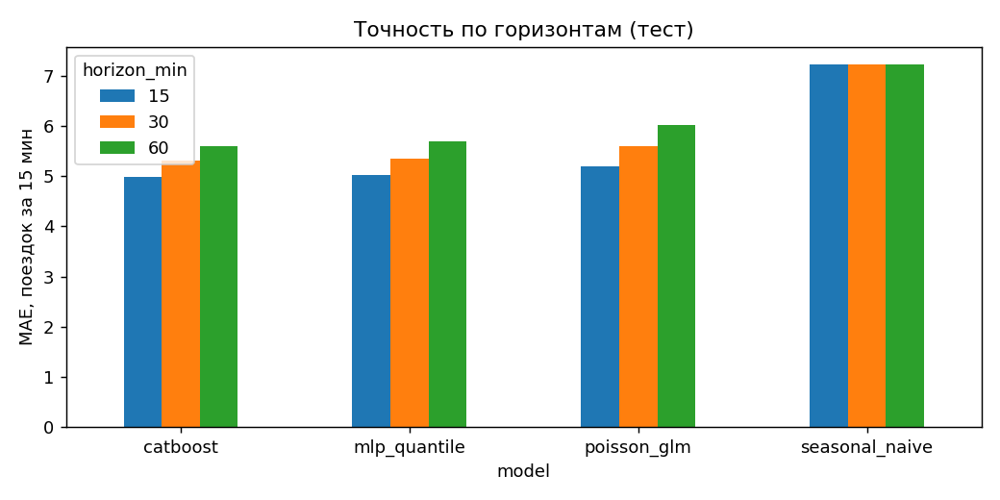

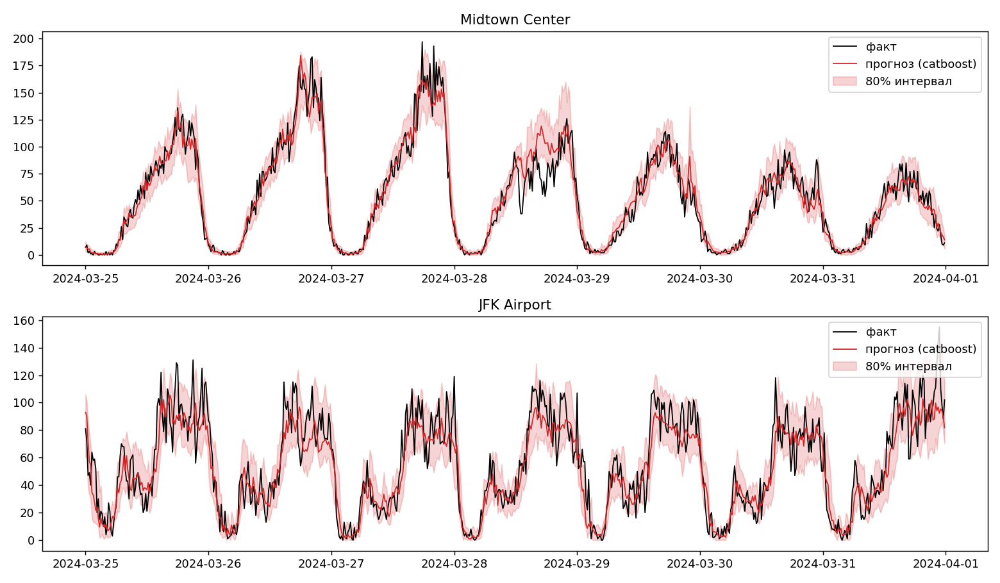

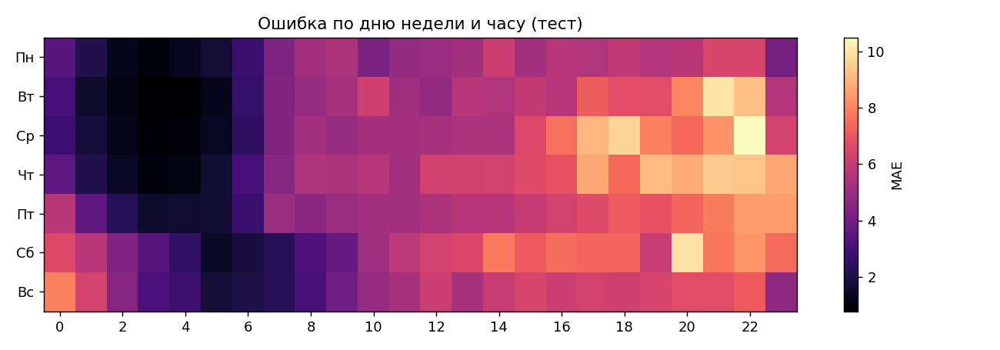

In [16]:
from IPython.display import Image, display
display(pd.read_csv(OUT / "metrics.csv").round(3))
for f in ["metrics_mae", "forecast_zones", "error_heatmap"]:
    display(Image(OUT / f"{f}.png"))
figs["demand_map"].show()
figs["error_map"].show()